# Binary Orientation Classifier: Forward vs Oriented

This notebook trains **Random Forest** and **XGBoost** binary classifiers whose target is whether the globally fastest algorithm for an original `(dataset, k)` instance belongs to the **Oriented** or **Forward** algorithm family.

It reuses the repository configuration and shared feature/runtime loading utilities where possible. Notebook-local functions are used only for the binary target, leakage-safe split, model fitting, and binary reporting.


## Experimental rule

Each original source instance contributes **one binary label**:

- `Oriented` if the globally fastest runtime among all 24 algorithms belongs to `ORIENTED_ALGOS`.
- `Forward` if it belongs to `NON_ORIENTED_ALGOS`.

The split is performed on the original instances; there is **no tie expansion** for this binary experiment. Exact cross-family runtime ties are detected and excluded by default because they do not have a unique binary target. This avoids arbitrarily labeling an instance whose global optimum belongs to both families.


In [1]:
from pathlib import Path
import sys

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "restructured_pipeline").exists():
    raise RuntimeError("Run this notebook from the repository root (kpex_ML_git).")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError("xgboost is required for the XGB experiment") from exc

from restructured_pipeline.src.features import (
    algorithms as ALL_ALGOS,
    ORIENTED_ALGOS,
    NON_ORIENTED_ALGOS,
    load_excel_data,
    process_kcore_list_to_statistics,
    post_process_data,
)

from restructured_pipeline.src.compare_wrong_predictions import filter_tolerance_sheet_for_important_failures

PROJECT_CONFIG = REPO_ROOT / "restructured_pipeline/configs/project.yaml"
SCHEME1_CONFIG = REPO_ROOT / "restructured_pipeline/configs/models_scheme1.yaml"
OUTPUT_DIR = REPO_ROOT / "restructured_pipeline/outputs/reports/binary_orientation_classifier"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with open(PROJECT_CONFIG, "r", encoding="utf-8") as f:
    project = yaml.safe_load(f)
with open(SCHEME1_CONFIG, "r", encoding="utf-8") as f:
    scheme1_cfg = yaml.safe_load(f)

FEATURE_COLS = list(project["features"]["feature_cols"])
TEST_SIZE = project["split_rules"]["defaults"]["test_size"]
RANDOM_STATE = project["split_rules"]["defaults"]["random_state"]

print("Features:", FEATURE_COLS)
print("Split:", 1-TEST_SIZE, "/", TEST_SIZE, " random_state=", RANDOM_STATE)
print("Algorithms:", len(ALL_ALGOS), "Oriented:", len(ORIENTED_ALGOS), "Forward:", len(NON_ORIENTED_ALGOS))


Features: ['k_value', 'n', 'm', 'd_avg', 'd_max', 'core_max', 'core_min', 'shell_num', 'shell_avgSize', 'shell_maxSize', 'shell_minSize', 'shell_stdSize']
Split: 0.8 / 0.2  random_state= 42
Algorithms: 24 Oriented: 12 Forward: 12


## Load the canonical runtime dataset

This uses the same `project.yaml` data configuration and `features.load_excel_data()` utility used by the pipeline. The 24 runtime columns are retained only to construct the binary target; model inputs remain the configured feature columns.


In [2]:
data_cfg = project["data"]
df = load_excel_data(
    data_cfg["file_path"],
    timeout_replacement=data_cfg["timeout_replacement"],
    y_cols=data_cfg["raw_target_columns"],
    sep=data_cfg["sep"],
    quotechar=data_cfg["quotechar"],
    engine=data_cfg["engine"],
    rename_columns=data_cfg["rename_columns"],
)

# Match the repository training preprocessing: load_excel_data() renames
# shell_sizes -> kcore_list, but the configured shell/core statistics are
# generated separately.
if "kcore_list" in df.columns:
    process_kcore_list_to_statistics(df, keep_col=False)

df = post_process_data(df)

required = [*FEATURE_COLS, *ALL_ALGOS]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns after feature preprocessing: {missing}")

print("Original rows:", len(df))
display(df[FEATURE_COLS].head())


Original rows: 4279


,k_value,n,m,d_avg,d_max,core_max,core_min,shell_num,shell_avgSize,shell_maxSize,shell_minSize,shell_stdSize
0,20,52328,1585220,30.294,9214,57,19,39,16785.102564,52328,1030,14354.722410
1,8,584,6059,10.375,322,12,8,5,564.400000,584,509,28.443628
2,9,584,6059,10.375,322,12,8,5,564.400000,584,509,28.443628
3,10,583,6051,10.379,321,12,9,4,559.500000,583,509,29.853810
4,4,144319,1072349,7.430,26,9,7,3,140266.333333,144319,132943,5188.210310


## Construct the binary target

We determine the minimum runtime in each 12-algorithm family. A row is `Oriented` when the Oriented minimum is strictly smaller, and `Forward` when the Forward minimum is strictly smaller. Cross-family exact ties are reported and removed rather than broken arbitrarily.


In [3]:
def build_orientation_target(frame: pd.DataFrame):
    out = frame.copy()
    oriented_min = out[list(ORIENTED_ALGOS)].apply(pd.to_numeric, errors="coerce").min(axis=1)
    forward_min = out[list(NON_ORIENTED_ALGOS)].apply(pd.to_numeric, errors="coerce").min(axis=1)

    out["oriented_best_runtime"] = oriented_min
    out["forward_best_runtime"] = forward_min
    out["orientation_target"] = np.where(
        oriented_min < forward_min, "Oriented",
        np.where(forward_min < oriented_min, "Forward", "Tie")
    )
    return out

binary_df = build_orientation_target(df)
print(binary_df["orientation_target"].value_counts(dropna=False))

tie_rows = binary_df[binary_df["orientation_target"].eq("Tie")].copy()
print(f"Cross-family exact ties excluded: {len(tie_rows)}")

binary_df = binary_df[~binary_df["orientation_target"].eq("Tie")].copy()
print("Rows used for binary classification:", len(binary_df))
display(binary_df["orientation_target"].value_counts().rename("rows").to_frame())


orientation_target
Oriented    3197
Forward      791
Tie          291
Name: count, dtype: int64
Cross-family exact ties excluded: 291
Rows used for binary classification: 3988


,rows
orientation_target,
Oriented,3197
Forward,791


## Leakage-safe train/test splits

Two original-row 80/20 splits are created:

- **`strat_y`** — stratified by Forward/Oriented target.
- **`strat_y_K`** — stratified by Forward/Oriented target + K using the existing `_train_test_split_k_aware()` helper.

The binary router does not expand targets. Both splits explicitly verify zero train/test source-row overlap and no duplicate held-out source instances.


In [4]:
X = binary_df[FEATURE_COLS].copy()
y = binary_df["orientation_target"].copy()

# ------------------------------------------------------------
# Two original-row split strategies.
# No target expansion is used for this binary router.
# ------------------------------------------------------------
from restructured_pipeline.src.data_splits import _train_test_split_k_aware

splits = {}

# 1) strat_y: stratify by Forward / Oriented target.
X_train_y, X_test_y, y_train_y, y_test_y = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)
splits["strat_y"] = (X_train_y, X_test_y, y_train_y, y_test_y)

# 2) strat_y_K: target + K using the existing K-aware splitter.
strat_yk_labels = (
    y.astype(str)
    + "_k"
    + binary_df.loc[X.index, "k_value"].astype(str)
)

X_train_yk, X_test_yk, y_train_yk, y_test_yk = _train_test_split_k_aware(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify_labels=strat_yk_labels,
    context_label="binary_orientation_strat_y_K",
)
splits["strat_y_K"] = (
    X_train_yk,
    X_test_yk,
    y_train_yk,
    y_test_yk,
)

split_audit_rows = []

for split_mode, (X_train, X_test, y_train, y_test) in splits.items():
    overlap = set(X_train.index) & set(X_test.index)

    assert not overlap, (
        f"{split_mode}: train/test leakage: {list(overlap)[:20]}"
    )
    assert not X_test.index.duplicated().any(), (
        f"{split_mode}: duplicate held-out source instances"
    )

    split_audit_rows.append({
        "split_mode": split_mode,
        "train_rows": len(X_train),
        "test_rows": len(X_test),
        "overlap": len(overlap),
        "duplicate_test_rows": int(X_test.index.duplicated().sum()),
        "train_forward": int(y_train.eq("Forward").sum()),
        "train_oriented": int(y_train.eq("Oriented").sum()),
        "test_forward": int(y_test.eq("Forward").sum()),
        "test_oriented": int(y_test.eq("Oriented").sum()),
    })

split_audit = pd.DataFrame(split_audit_rows)
display(split_audit)


binary_orientation_strat_y_K: forced 0 row(s) into training before the K-aware split.
binary_orientation_strat_y_K: completed true target+K stratification on 22 combined class(es).
binary_orientation_strat_y_K: final train/test sizes = 3190/798.


,split_mode,train_rows,test_rows,overlap,duplicate_test_rows,train_forward,train_oriented,test_forward,test_oriented
0,strat_y,3190,798,0,0,633,2557,158,640
1,strat_y_K,3190,798,0,0,634,2556,157,641


## Reuse model configuration

The notebook reads the existing Scheme 1 RF/XGB YAML and uses the `strat_y` hyperparameters as the starting configuration. Parameters specific to multiclass XGBoost are removed/overridden for binary logistic classification. You can replace these dictionaries with a dedicated binary YAML later without changing the rest of the notebook.


In [5]:
def find_family_config(cfg, family, split_mode):
    root = cfg.get("scheme1", cfg)
    fam = root.get(family, {})
    variants = fam.get("variants", fam)

    prefix = "rf" if family == "random_forest" else "xgb"
    key = f"{prefix}_{split_mode}"

    if key in variants:
        return dict(
            variants[key].get(
                "hyperparameters",
                variants[key],
            )
        )

    return {}


def binary_model_params(family, split_mode):
    params = find_family_config(
        scheme1_cfg,
        family,
        split_mode,
    )

    if not params:
        if family == "random_forest":
            params = dict(
                n_estimators=200,
                max_depth=20,
                min_samples_split=4,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            )
        else:
            params = dict(
                n_estimators=400,
                max_depth=10,
                learning_rate=0.1,
                subsample=0.8,
                random_state=RANDOM_STATE,
            )

    if family == "xgboost":
        params.pop("num_class", None)
        params.pop("use_label_encoder", None)
        params["objective"] = "binary:logistic"
        params["eval_metric"] = "logloss"
        params.setdefault("random_state", RANDOM_STATE)

    return params


for split_mode in splits:
    print(
        split_mode,
        "RF:",
        binary_model_params("random_forest", split_mode),
    )
    print(
        split_mode,
        "XGB:",
        binary_model_params("xgboost", split_mode),
    )


strat_y RF: {'n_estimators': 200, 'max_depth': 20, 'min_samples_split': 4, 'class_weight': 'balanced', 'random_state': 42}
strat_y XGB: {'objective': 'binary:logistic', 'n_estimators': 400, 'max_depth': 10, 'learning_rate': 0.1, 'subsample': 0.8, 'random_state': 42, 'eval_metric': 'logloss'}
strat_y_K RF: {'n_estimators': 400, 'max_depth': 20, 'min_samples_split': 2, 'class_weight': 'balanced', 'random_state': 42}
strat_y_K XGB: {'objective': 'binary:logistic', 'n_estimators': 400, 'max_depth': 10, 'learning_rate': 0.1, 'subsample': 0.8, 'random_state': 42, 'eval_metric': 'logloss'}


## Train RF and XGB

Both models see exactly the same training and held-out test instances. XGBoost uses a `LabelEncoder` only because it expects numeric binary labels; reported class names remain `Forward` and `Oriented`.


In [6]:
models = {}

for split_mode, (X_train, X_test, y_train, y_test) in splits.items():
    # Random Forest
    rf_params = binary_model_params(
        "random_forest",
        split_mode,
    )
    rf = RandomForestClassifier(**rf_params)
    rf.fit(X_train, y_train)
    models[(split_mode, "Random Forest")] = (rf, None)

    # XGBoost
    xgb_params = binary_model_params(
        "xgboost",
        split_mode,
    )

    le = LabelEncoder()
    le.fit(["Forward", "Oriented"])
    y_train_enc = le.transform(y_train)

    xgb = XGBClassifier(**xgb_params)
    xgb.fit(X_train, y_train_enc)
    models[(split_mode, "XGBoost")] = (xgb, le)

print("Trained models:")
for key in models:
    print(" ", key)


Trained models:
  ('strat_y', 'Random Forest')
  ('strat_y', 'XGBoost')
  ('strat_y_K', 'Random Forest')
  ('strat_y_K', 'XGBoost')


## Metrics

For each model the notebook reports:

- Accuracy
- Macro precision / recall / F1
- Weighted precision / recall / **weighted F1**
- Forward precision / recall / F1
- Oriented precision / recall / F1
- Class support
- Confusion matrix (displayed and saved as PNG)

Macro metrics weight the two classes equally; weighted metrics weight by class frequency.



strat_y — Random Forest — Held-out Test
              precision    recall  f1-score   support

     Forward     0.6644    0.6139    0.6382       158
    Oriented     0.9064    0.9234    0.9149       640

    accuracy                         0.8622       798
   macro avg     0.7854    0.7687    0.7765       798
weighted avg     0.8585    0.8622    0.8601       798



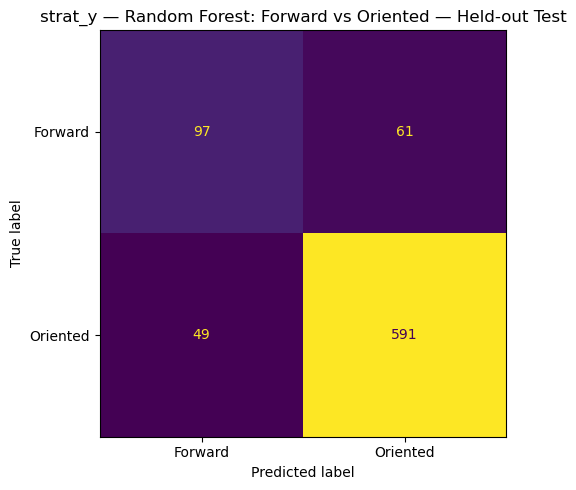


strat_y — Random Forest — Entire Dataset
              precision    recall  f1-score   support

     Forward     0.8871    0.9140    0.9004       791
    Oriented     0.9786    0.9712    0.9749      3197

    accuracy                         0.9599      3988
   macro avg     0.9328    0.9426    0.9376      3988
weighted avg     0.9604    0.9599    0.9601      3988



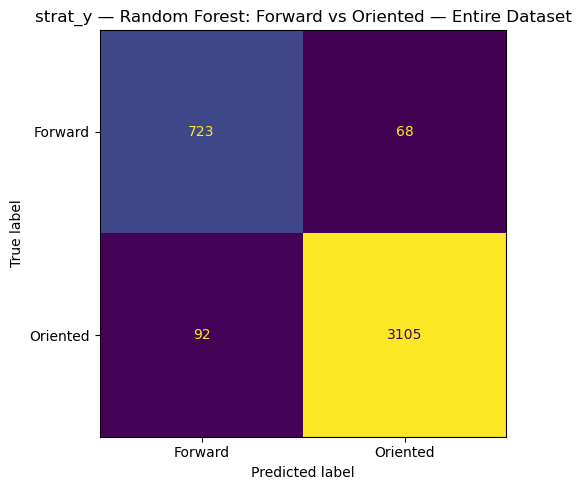


strat_y — XGBoost — Held-out Test
              precision    recall  f1-score   support

     Forward     0.6788    0.5886    0.6305       158
    Oriented     0.9017    0.9313    0.9162       640

    accuracy                         0.8634       798
   macro avg     0.7902    0.7599    0.7734       798
weighted avg     0.8575    0.8634    0.8596       798



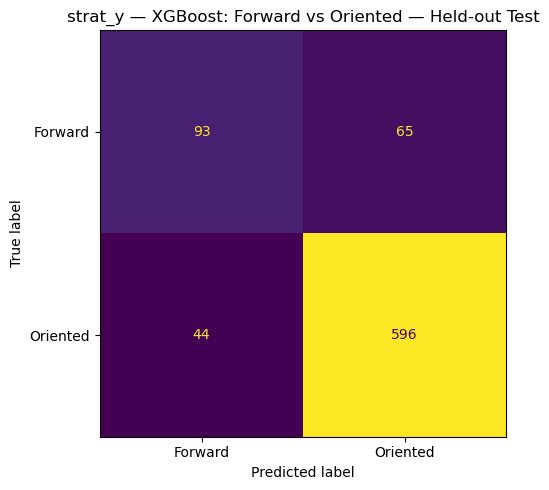


strat_y — XGBoost — Entire Dataset
              precision    recall  f1-score   support

     Forward     0.9408    0.9039    0.9220       791
    Oriented     0.9765    0.9859    0.9812      3197

    accuracy                         0.9697      3988
   macro avg     0.9586    0.9449    0.9516      3988
weighted avg     0.9694    0.9697    0.9694      3988



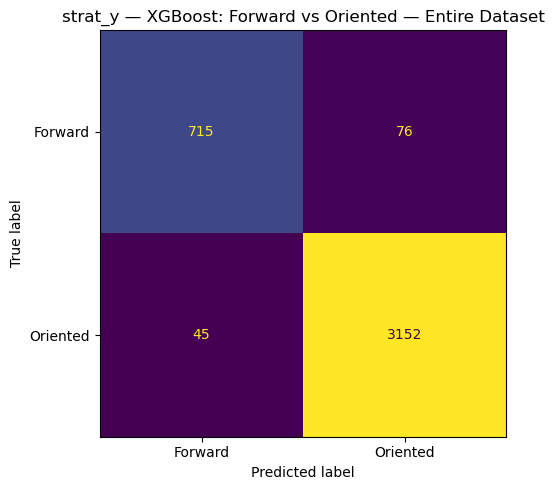


strat_y_K — Random Forest — Held-out Test
              precision    recall  f1-score   support

     Forward     0.6838    0.5924    0.6348       157
    Oriented     0.9033    0.9329    0.9179       641

    accuracy                         0.8659       798
   macro avg     0.7936    0.7626    0.7763       798
weighted avg     0.8601    0.8659    0.8622       798



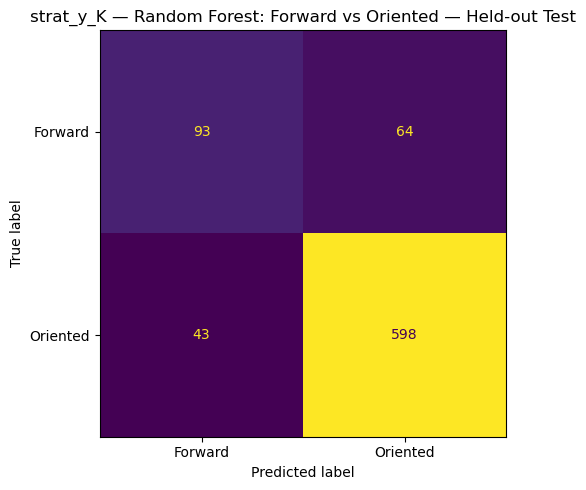


strat_y_K — Random Forest — Entire Dataset
              precision    recall  f1-score   support

     Forward     0.9248    0.9178    0.9213       791
    Oriented     0.9797    0.9815    0.9806      3197

    accuracy                         0.9689      3988
   macro avg     0.9523    0.9497    0.9510      3988
weighted avg     0.9688    0.9689    0.9689      3988



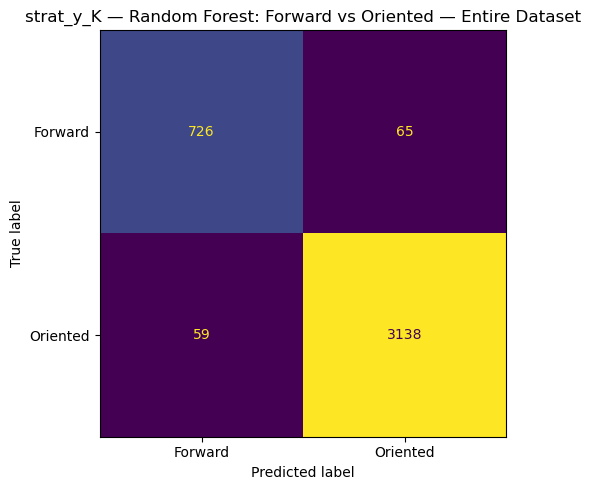


strat_y_K — XGBoost — Held-out Test
              precision    recall  f1-score   support

     Forward     0.7037    0.6051    0.6507       157
    Oriented     0.9065    0.9376    0.9218       641

    accuracy                         0.8722       798
   macro avg     0.8051    0.7713    0.7862       798
weighted avg     0.8666    0.8722    0.8684       798



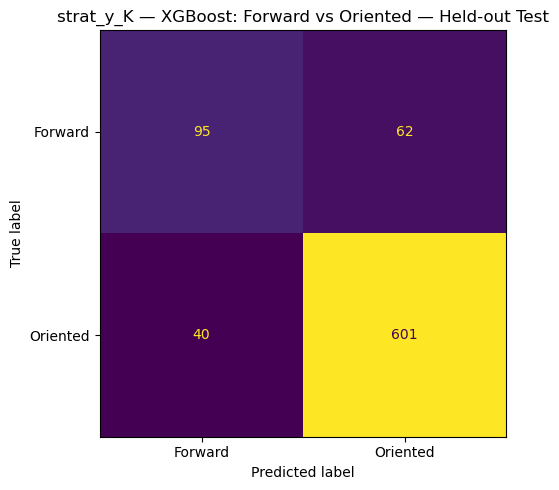


strat_y_K — XGBoost — Entire Dataset
              precision    recall  f1-score   support

     Forward     0.9421    0.9052    0.9233       791
    Oriented     0.9768    0.9862    0.9815      3197

    accuracy                         0.9702      3988
   macro avg     0.9594    0.9457    0.9524      3988
weighted avg     0.9699    0.9702    0.9699      3988



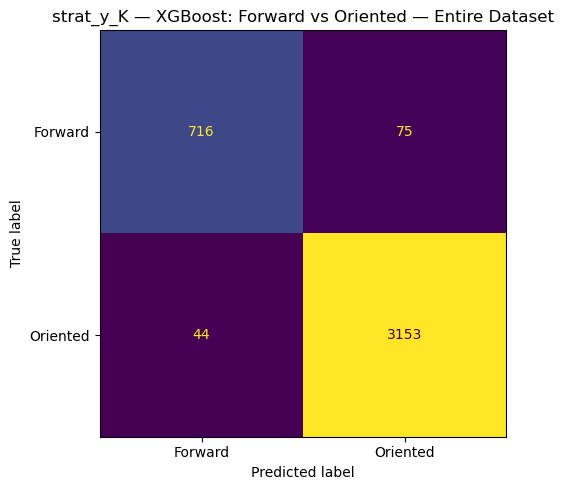

,Split,Model,Evaluation Scope,Rows,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Forward Precision,Forward Recall,Forward F1,Forward Support,Oriented Precision,Oriented Recall,Oriented F1,Oriented Support
0,strat_y,Random Forest,Held-out Test,798,0.8622,0.7854,0.7687,0.7765,0.8585,0.8622,0.8601,0.6644,0.6139,0.6382,158,0.9064,0.9234,0.9149,640
1,strat_y,Random Forest,Entire Dataset,3988,0.9599,0.9328,0.9426,0.9376,0.9604,0.9599,0.9601,0.8871,0.9140,0.9004,791,0.9786,0.9712,0.9749,3197
2,strat_y,XGBoost,Held-out Test,798,0.8634,0.7902,0.7599,0.7734,0.8575,0.8634,0.8596,0.6788,0.5886,0.6305,158,0.9017,0.9312,0.9162,640
3,strat_y,XGBoost,Entire Dataset,3988,0.9697,0.9586,0.9449,0.9516,0.9694,0.9697,0.9694,0.9408,0.9039,0.9220,791,0.9765,0.9859,0.9812,3197
4,strat_y_K,Random Forest,Held-out Test,798,0.8659,0.7936,0.7626,0.7763,0.8601,0.8659,0.8622,0.6838,0.5924,0.6348,157,0.9033,0.9329,0.9179,641
5,strat_y_K,Random Forest,Entire Dataset,3988,0.9689,0.9523,0.9497,0.9510,0.9688,0.9689,0.9689,0.9248,0.9178,0.9213,791,0.9797,0.9815,0.9806,3197
6,strat_y_K,XGBoost,Held-out Test,798,0.8722,0.8051,0.7713,0.7862,0.8666,0.8722,0.8684,0.7037,0.6051,0.6507,157,0.9065,0.9376,0.9218,641
7,strat_y_K,XGBoost,Entire Dataset,3988,0.9702,0.9594,0.9457,0.9524,0.9699,0.9702,0.9699,0.9421,0.9052,0.9233,791,0.9768,0.9862,0.9815,3197


In [7]:
LABELS = ["Forward", "Oriented"]

def evaluate_on_scope(
    split_mode,
    name,
    model,
    X_eval,
    y_eval,
    scope,
    encoder=None,
):
    raw_pred = model.predict(X_eval)
    y_pred = (
        encoder.inverse_transform(raw_pred.astype(int))
        if encoder is not None
        else raw_pred
    )

    acc = accuracy_score(y_eval, y_pred)

    macro_p, macro_r, macro_f1, _ = (
        precision_recall_fscore_support(
            y_eval,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0,
        )
    )

    weighted_p, weighted_r, weighted_f1, _ = (
        precision_recall_fscore_support(
            y_eval,
            y_pred,
            labels=LABELS,
            average="weighted",
            zero_division=0,
        )
    )

    per_p, per_r, per_f1, support = (
        precision_recall_fscore_support(
            y_eval,
            y_pred,
            labels=LABELS,
            average=None,
            zero_division=0,
        )
    )

    row = {
        "Split": split_mode,
        "Model": name,
        "Evaluation Scope": scope,
        "Rows": len(y_eval),
        "Accuracy": acc,
        "Macro Precision": macro_p,
        "Macro Recall": macro_r,
        "Macro F1": macro_f1,
        "Weighted Precision": weighted_p,
        "Weighted Recall": weighted_r,
        "Weighted F1": weighted_f1,
    }

    for label, p_, r_, f_, n_ in zip(
        LABELS,
        per_p,
        per_r,
        per_f1,
        support,
    ):
        row[f"{label} Precision"] = p_
        row[f"{label} Recall"] = r_
        row[f"{label} F1"] = f_
        row[f"{label} Support"] = int(n_)

    print(
        f"\n{split_mode} — {name} — {scope}"
    )
    print("=" * 60)
    print(
        classification_report(
            y_eval,
            y_pred,
            labels=LABELS,
            digits=4,
            zero_division=0,
        )
    )

    cm = confusion_matrix(
        y_eval,
        y_pred,
        labels=LABELS,
    )

    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(
        cm,
        display_labels=LABELS,
    ).plot(
        ax=ax,
        values_format="d",
        colorbar=False,
    )

    ax.set_title(
        f"{split_mode} — {name}: "
        f"Forward vs Oriented — {scope}"
    )
    fig.tight_layout()

    scope_slug = (
        scope.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )
    model_slug = (
        name.lower()
        .replace(" ", "_")
    )

    png = OUTPUT_DIR / (
        f"confusion_matrix_{split_mode}_"
        f"{model_slug}_{scope_slug}.png"
    )

    fig.savefig(
        png,
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

    return (
        row,
        pd.DataFrame(
            {
                "true": np.asarray(y_eval),
                "predicted": np.asarray(y_pred),
            },
            index=X_eval.index,
        ),
    )


metric_rows = []
prediction_frames = {}

X_entire = binary_df[FEATURE_COLS].copy()
y_entire = binary_df["orientation_target"].copy()

for split_mode, (X_train, X_test, y_train, y_test) in splits.items():
    for name in ("Random Forest", "XGBoost"):
        model, encoder = models[(split_mode, name)]

        for scope, X_eval, y_eval in (
            ("Held-out Test", X_test, y_test),
            ("Entire Dataset", X_entire, y_entire),
        ):
            metric, preds = evaluate_on_scope(
                split_mode,
                name,
                model,
                X_eval,
                y_eval,
                scope,
                encoder,
            )

            metric_rows.append(metric)

            prediction_frames[
                (split_mode, name, scope)
            ] = preds

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df.round(4))


## Compact comparison table

This is the main table to use in a report or slide. Accuracy alone can hide asymmetric behavior, so the two class-specific F1 scores and weighted F1 should be considered alongside it.


In [8]:
slide_cols = [
    "Split", "Model", "Evaluation Scope", "Rows", "Accuracy", "Weighted F1",
    "Forward Precision", "Forward Recall", "Forward F1",
    "Oriented Precision", "Oriented Recall", "Oriented F1",
]
display(metrics_df[slide_cols].round(4))


,Split,Model,Evaluation Scope,Rows,Accuracy,Weighted F1,Forward Precision,Forward Recall,Forward F1,Oriented Precision,Oriented Recall,Oriented F1
0,strat_y,Random Forest,Held-out Test,798,0.8622,0.8601,0.6644,0.6139,0.6382,0.9064,0.9234,0.9149
1,strat_y,Random Forest,Entire Dataset,3988,0.9599,0.9601,0.8871,0.9140,0.9004,0.9786,0.9712,0.9749
2,strat_y,XGBoost,Held-out Test,798,0.8634,0.8596,0.6788,0.5886,0.6305,0.9017,0.9312,0.9162
3,strat_y,XGBoost,Entire Dataset,3988,0.9697,0.9694,0.9408,0.9039,0.9220,0.9765,0.9859,0.9812
4,strat_y_K,Random Forest,Held-out Test,798,0.8659,0.8622,0.6838,0.5924,0.6348,0.9033,0.9329,0.9179
5,strat_y_K,Random Forest,Entire Dataset,3988,0.9689,0.9689,0.9248,0.9178,0.9213,0.9797,0.9815,0.9806
6,strat_y_K,XGBoost,Held-out Test,798,0.8722,0.8684,0.7037,0.6051,0.6507,0.9065,0.9376,0.9218
7,strat_y_K,XGBoost,Entire Dataset,3988,0.9702,0.9699,0.9421,0.9052,0.9233,0.9768,0.9862,0.9815


## Wrong predictions and important failures

This section follows the established router failure-analysis logic. For every prediction, the denominator is the **global minimum runtime across all 24 algorithms**. The predicted Forward/Oriented family is given its best achievable runtime. `best_algorithms_in_predicted_branch` deliberately lists **all algorithms tied for that best runtime**; the binary classifier predicts a family, not a single algorithm.

The existing `filter_tolerance_sheet_for_important_failures()` function is reused for important-failure filtering.


In [9]:
BRANCH_ALGOS={"Forward":list(NON_ORIENTED_ALGOS),"Oriented":list(ORIENTED_ALGOS)}

def _best_branch_runtime(source_row,branch):
    vals=[(float(source_row[a]),a) for a in BRANCH_ALGOS[branch]]
    best=min(rt for rt,_ in vals)
    return best,[a for rt,a in vals if rt==best]

def _global_24_fastest_runtime(source_row):
    vals=[(float(source_row[a]),a) for a in ALL_ALGOS]
    best=min(rt for rt,_ in vals)
    return best,[a for rt,a in vals if rt==best]

def _severity_label(x):
    if pd.isna(x): return "Unknown"
    if x<=0.05: return "≤5%"
    if x<=0.20: return "5–20%"
    if x<=1.00: return "20–100%"
    return ">100%"

def build_binary_failure_analysis(prediction_frames,source_df,default_split_mode="strat_y"):
    wrong_detail={}; important_detail={}; summary=[]
    for key,pred_df in prediction_frames.items():
        if len(key)==2: model_name,scope=key; split_mode=default_split_mode
        else: split_mode,model_name,scope=key
        model="RF" if str(model_name).lower() in {"random forest","rf","random_forest"} else "XGB"
        scope_name="test_data" if scope=="Held-out Test" else "entire_data" if scope=="Entire Dataset" else str(scope)
        rows=[]
        for idx,p in pred_df.iterrows():
            src=source_df.loc[idx]; true=str(p["true"]); predicted=str(p["predicted"])
            ft,fa=_global_24_fastest_runtime(src); pt,pa=_best_branch_runtime(src,predicted)
            gap=pt-ft; gap_ratio=gap/ft if ft else np.nan
            rows.append({"source_row_index":idx,"dataset":src.get("dataset"),"k_value":src.get("k_value"),
                         "split_mode":split_mode,"model":model,"scope":scope_name,
                         "true_target":true,"predicted_target":predicted,"correct":true==predicted,
                         "fastest_time":ft,"fastest_algorithm":" | ".join(fa),"predicted_time":pt,
                         "best_algorithms_in_predicted_branch":" | ".join(pa),"time_gap":gap,
                         "time_gap_ratio":gap_ratio,"time_ratio":pt/ft if ft else np.nan,
                         "failure_severity":_severity_label(gap_ratio)})
        enriched=pd.DataFrame(rows); wrong=enriched.loc[~enriched.correct].copy()
        important,stats=filter_tolerance_sheet_for_important_failures(wrong)
        dkey=(split_mode,model,scope_name); wrong_detail[dkey]=wrong; important_detail[dkey]=important
        summary.append({"split_mode":split_mode,"model":model,"scope":scope_name,"total_predictions":len(enriched),
                        "wrong_predictions":len(wrong),"important_failures":len(important),
                        "wrong_prediction_percent":round(100*len(wrong)/len(enriched),2) if len(enriched) else 0,
                        "important_given_wrong_percent":round(100*len(important)/len(wrong),2) if len(wrong) else 0,
                        "important_of_all_percent":round(100*len(important)/len(enriched),2) if len(enriched) else 0})
    summary=pd.DataFrame(summary)
    overlaps=[]
    for (split_mode,model),_ in summary.groupby(["split_mode","model"],sort=False):
        test=important_detail.get((split_mode,model,"test_data"),pd.DataFrame())
        entire=important_detail.get((split_mode,model,"entire_data"),pd.DataFrame())
        tk=set(zip(test.dataset.astype(str),test.k_value)) if not test.empty else set()
        ek=set(zip(entire.dataset.astype(str),entire.k_value)) if not entire.empty else set()
        overlaps.append({"split_mode":split_mode,"model":model,"test_important_failures":len(test),
                         "entire_important_failures":len(entire),"overlapping_dataset_k_cases":len(tk&ek),
                         "test_only":len(tk-ek),"entire_only":len(ek-tk)})
    overlap=pd.DataFrame(overlaps)
    return summary.merge(overlap,on=["split_mode","model"],how="left"),wrong_detail,important_detail

failure_summary,wrong_failure_detail,important_failure_detail=build_binary_failure_analysis(
    prediction_frames,binary_df,default_split_mode="strat_y")
display(failure_summary)


,split_mode,model,scope,total_predictions,wrong_predictions,important_failures,wrong_prediction_percent,important_given_wrong_percent,important_of_all_percent,test_important_failures,entire_important_failures,overlapping_dataset_k_cases,test_only,entire_only
0,strat_y,RF,test_data,798,110,29,13.78,26.36,3.63,29,41,29,0,12
1,strat_y,RF,entire_data,3988,160,41,4.01,25.62,1.03,29,41,29,0,12
2,strat_y,XGB,test_data,798,109,34,13.66,31.19,4.26,34,34,34,0,0
3,strat_y,XGB,entire_data,3988,121,34,3.03,28.10,0.85,34,34,34,0,0
4,strat_y_K,RF,test_data,798,107,29,13.41,27.10,3.63,29,31,29,0,2
5,strat_y_K,RF,entire_data,3988,124,31,3.11,25.00,0.78,29,31,29,0,2
6,strat_y_K,XGB,test_data,798,102,29,12.78,28.43,3.63,29,31,29,0,2
7,strat_y_K,XGB,entire_data,3988,119,31,2.98,26.05,0.78,29,31,29,0,2


### Failure workbooks

The important-failure workbook contains a `summary` plus one detail sheet per available split/model/scope. With both `strat_y` and `strat_y_K` prediction frames this is **8 detail sheets**: RF/XGB × test/entire × two stratifications.


In [14]:
DETAIL_COLUMNS=["source_row_index","dataset","k_value","split_mode","model","scope","true_target","predicted_target",
"fastest_time","fastest_algorithm","predicted_time","time_ratio","best_algorithms_in_predicted_branch",]
# "time_gap","time_gap_ratio","time_ratio","failure_severity"]

def sheet_name(k):
    split,model,scope=k
    return f"{split}_{model}_{'test' if scope=='test_data' else 'entire'}"[:31]

wrong_path=OUTPUT_DIR/"binary_orientation_wrong_predictions.xlsx"
important_path=OUTPUT_DIR/"binary_orientation_important_failures.xlsx"

with pd.ExcelWriter(wrong_path,engine="openpyxl") as w:
    failure_summary.to_excel(w,sheet_name="summary",index=False)
    for k,f in wrong_failure_detail.items(): f[DETAIL_COLUMNS].to_excel(w,sheet_name=sheet_name(k),index=False)

with pd.ExcelWriter(important_path,engine="openpyxl") as w:
    failure_summary.to_excel(w,sheet_name="summary",index=False)
    for k,f in important_failure_detail.items(): f[DETAIL_COLUMNS].to_excel(w,sheet_name=sheet_name(k),index=False)

failure_summary.to_csv(OUTPUT_DIR/"wrong_and_important_failure_summary.csv",index=False)
print("Wrong:",wrong_path)
print("Important:",important_path)


Wrong: d:\Studies\Research\Da_Project\kpex_ML_git\restructured_pipeline\outputs\reports\binary_orientation_classifier\binary_orientation_wrong_predictions.xlsx
Important: d:\Studies\Research\Da_Project\kpex_ML_git\restructured_pipeline\outputs\reports\binary_orientation_classifier\binary_orientation_important_failures.xlsx


### Failure severity summary

This separates near-optimal mistakes from expensive routing mistakes using relative overhead against the global 24-algorithm optimum.


In [11]:
severity=[]
for k,wrong in wrong_failure_detail.items():
    for population,f in (("Wrong Predictions",wrong),("Important Failures",important_failure_detail[k])):
        counts=f.failure_severity.value_counts().to_dict()
        severity.append({"split_mode":k[0],"model":k[1],"scope":k[2],"population":population,"rows":len(f),
                         "≤5%":counts.get("≤5%",0),"5–20%":counts.get("5–20%",0),
                         "20–100%":counts.get("20–100%",0),">100%":counts.get(">100%",0)})
failure_severity_summary=pd.DataFrame(severity)
display(failure_severity_summary)
failure_severity_summary.to_csv(OUTPUT_DIR/"failure_severity_summary.csv",index=False)


,split_mode,model,scope,population,rows,≤5%,5–20%,20–100%,>100%
0,strat_y,RF,test_data,Wrong Predictions,110,11,32,43,24
1,strat_y,RF,test_data,Important Failures,29,0,0,17,12
2,strat_y,RF,entire_data,Wrong Predictions,160,20,45,61,34
3,strat_y,RF,entire_data,Important Failures,41,0,0,21,20
4,strat_y,XGB,test_data,Wrong Predictions,109,11,33,39,26
5,strat_y,XGB,test_data,Important Failures,34,0,0,18,16
6,strat_y,XGB,entire_data,Wrong Predictions,121,17,38,40,26
7,strat_y,XGB,entire_data,Important Failures,34,0,0,18,16
8,strat_y_K,RF,test_data,Wrong Predictions,107,10,32,38,27
9,strat_y_K,RF,test_data,Important Failures,29,0,0,14,15


## Save reproducible outputs

The metrics, test predictions, and exact train/test source indices are saved so the binary experiment can be audited and reproduced.


In [12]:
metrics_path = OUTPUT_DIR / "binary_orientation_metrics_test_and_entire.csv"
metrics_df.to_csv(metrics_path, index=False)

for (split_mode, name, scope), pred_df in prediction_frames.items():
    model_slug = name.lower().replace(" ", "_")
    scope_slug = (
        scope.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    pred_df.to_csv(
        OUTPUT_DIR
        / f"{split_mode}_{scope_slug}_predictions_{model_slug}.csv",
        index=True,
        index_label="source_row_index",
    )

for split_mode, (X_train, X_test, _, _) in splits.items():
    pd.DataFrame(
        {"source_row_index": X_train.index}
    ).to_csv(
        OUTPUT_DIR / f"train_indices_{split_mode}.csv",
        index=False,
    )

    pd.DataFrame(
        {"source_row_index": X_test.index}
    ).to_csv(
        OUTPUT_DIR / f"test_indices_{split_mode}.csv",
        index=False,
    )

print("Saved metrics:", metrics_path)
print("Output directory:", OUTPUT_DIR)


Saved metrics: d:\Studies\Research\Da_Project\kpex_ML_git\restructured_pipeline\outputs\reports\binary_orientation_classifier\binary_orientation_metrics_test_and_entire.csv
Output directory: d:\Studies\Research\Da_Project\kpex_ML_git\restructured_pipeline\outputs\reports\binary_orientation_classifier


## How to interpret the experiment

1. **Accuracy** answers how often the model chooses the correct algorithm family.
2. **Forward/Oriented recall** tells you whether one family is systematically missed.
3. **Forward/Oriented precision** tells you how trustworthy a prediction of that family is.
4. **Per-class F1** balances precision and recall for each family.
5. **Weighted F1** summarizes performance while accounting for class prevalence.
6. **Confusion matrices** make directional errors visible: Forward→Oriented versus Oriented→Forward.

This binary model can later act as a router: first predict the family, then invoke the corresponding 12-class Scheme 4 model. The binary router should be evaluated independently before combining its errors with the downstream family classifier.
